# TOY STAR FORMATION IN 3D USING SMOOTHED PARTICLE HYDRODYNAMICS

In [1]:
from matplotlib import pyplot as plt
import numpy as np
from numba import jit

## Read in Data

In [2]:
initial_data = np.loadtxt('random_distribution.dat')

In [3]:
len(initial_data), np.shape(initial_data)

(1000, (1000, 7))

1000 rows for 1000 particles, the columns are given as x,y,z,vx,vy,vz,m

## SPH Helper Functions

In [4]:
@jit(nopython=True)
def norm(x1,y1,z1,x2,y2,z2):
    return np.sqrt((x2-x1)**2.0 + (y2-y1)**2.0 + (z2-z1)**2.0)

In [5]:
@jit(nopython=True)
def kernel_3d(h, r): #this r is given by the norm function, which is the r_tilda in the slides
    coeff = 8.0/(np.pi*h**3.0)
    
    if 0<= (r/h) <0.5:
        return coeff*(6.0*(r/h)**3.0 -6.0*(r/h)**2.0 +1.0)
    elif 0.5<= (r/h) <=1:
        return coeff*2.0*(1-(r/h))**3.0
    elif (r/h)>1:
        return 0.0

In [6]:
@jit(nopython=True)
def kernel_3d_diff(h,r): #this r is given by the norm function, which is the r_tilda in the slides
    coeff = (6.0*8.0)/(np.pi*h**4.0)
    
    if 0<= (r/h) <0.5:
        return coeff*(3.0*(r/h)**2.0 -2.0*(r/h))
    elif 0.5<= (r/h) <=1:
        return coeff*-1.0*(1 - (r/h))**2.0
    elif (r/h)>1:
        return 0.0

$$ \nabla_i W_{ij} = \frac{r_i - r_j}{|r_i - r_j|} \frac{\partial W_{ij}}{\partial (r_i - r_j)} $$

$$ \rho_i = \sum_j^N m_j W_{ij} $$

$$ p_i = \kappa \rho_i^\gamma$$

$$ \frac{dv_i}{dt} = - \sum_j^N m_j \left( \frac{p_i}{\rho_i^2} + \frac{p_j}{\rho_j^2}\right) \nabla_i W_{ij}$$

Force from linear acceleration: $$a = - \lambda x$$

Force from damping: $$a = - \nu v$$

In [7]:
@jit(nopython=True)
def SPH_polytropic(initial_data, h, tend, dt, kappa, gamma, lam, nu):

    N = np.shape(initial_data)[0] #no. of particles
 
    rho = np.zeros(N)
    pressure = np.zeros(N)
    acc_1 = np.zeros((N,3)) # N particles with 3 components of acceleration....
    acc_2 = np.zeros((N,3))
    acc_3 = np.zeros((N,3))
    cs = np.zeros(N)
    
    # using fixed time step dt, as per the guidelines of the problem....!
    t = np.linspace(0,tend, int((tend-0)/(dt) +1.0))
    data = np.zeros((len(t), N, np.shape(initial_data)[1]))
    data[0,:,:] = np.copy(initial_data)
    

    print('The total integration length is: '+str(len(t)))

    for i in range(0, len(t)-1):
        
        rho[:] = 0.0
        acc_1[:,:] = 0.0
        acc_2[:,:] = 0.0
        acc_3[:,:] = 0.0
        
        #1. find density
        for j in range(0, N):
            for k in range(0,N):
                rho[j] = rho[j] + data[i][k][6]*kernel_3d(h, norm(data[i][j][0],data[i][j][1], data[i][j][2], data[i][k][0],data[i][k][1],data[i][k][2]))
    
        #2. find sound speed
        #this data is unused
        cs = np.sqrt(kappa*gamma*(rho**(gamma-1.0)))
    
        #3. find pressure for polytropic gas
        pressure = kappa*(rho**gamma)

        #4,5,6. find acceleration due to pressure of the fluid,linearized gravity, and damping
        for j in range(0,N):
            for k in range(0,N):
                
                r = norm(data[i][j][0],data[i][j][1], data[i][j][2], data[i][k][0],data[i][k][1],data[i][k][2])
                if r!=0:
                    acc_1[j,0] = acc_1[j,0] - data[i][k][6]*((pressure[j]/rho[j]**2.0) + (pressure[k]/rho[k]**2.0))*((data[i][j][0] - data[i][k][0])/r)*kernel_3d_diff(h, r)
                    acc_1[j,1] = acc_1[j,1] - data[i][k][6]*((pressure[j]/rho[j]**2.0) + (pressure[k]/rho[k]**2.0))*((data[i][j][1] - data[i][k][1])/r)*kernel_3d_diff(h, r)
                    acc_1[j,2] = acc_1[j,2] - data[i][k][6]*((pressure[j]/rho[j]**2.0) + (pressure[k]/rho[k]**2.0))*((data[i][j][2] - data[i][k][2])/r)*kernel_3d_diff(h, r)
            
        acc_2 = - lam*data[i,:,0:3]
        acc_3 = - nu*data[i,:,3:6]    
    
        #7. integrate!
        #Euler-Cromer routine; use future velocities to find future coordinates
       
        data[i+1,:,3:6] = data[i,:,3:6] + (acc_1 + acc_2 + acc_3)*dt
        data[i+1,:,0:3] = data[i,:,0:3] + data[i+1,:,3:6]*dt

        #copy the mass
        data[i+1,:,6] = data[0,:,6]


        if (i+1)%100 == 0:
            print('Finished time slice index:'+str(i+1))
        

    return t, data

In [8]:
result_time, result_data = SPH_polytropic(initial_data, h=0.2, tend=30.0, dt=0.01, kappa = 0.1, gamma=2.0, lam = 2.01203286081606, nu=0.1)

The total integration length is: 3001
Finished time slice index:100
Finished time slice index:200
Finished time slice index:300
Finished time slice index:400
Finished time slice index:500
Finished time slice index:600
Finished time slice index:700
Finished time slice index:800
Finished time slice index:900
Finished time slice index:1000
Finished time slice index:1100
Finished time slice index:1200
Finished time slice index:1300
Finished time slice index:1400
Finished time slice index:1500
Finished time slice index:1600
Finished time slice index:1700
Finished time slice index:1800
Finished time slice index:1900
Finished time slice index:2000
Finished time slice index:2100
Finished time slice index:2200
Finished time slice index:2300
Finished time slice index:2400
Finished time slice index:2500
Finished time slice index:2600
Finished time slice index:2700
Finished time slice index:2800
Finished time slice index:2900
Finished time slice index:3000


## Visualize

In [12]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import PillowWriter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [63]:
def plot_frame(index, ax, angle1, angle2):
    # remove previous inset so they don't pile up across frames
    if hasattr(ax, '_vrms_inset'):
        ax._vrms_inset.remove()
    
    # vrms(t) for every slice from 0 up to and including `index`
    vx = result_data[:index+1, :, 3]
    vy = result_data[:index+1, :, 4]
    vz = result_data[:index+1, :, 5]
    vrms = np.sqrt(np.mean(vx**2 + vy**2 + vz**2, axis=1))  # shape (index+1,)

    ax.text2D(0.05, 0.90, "t: " + str("%.3f" % (result_time[index])), size=20, c='yellow', transform=ax.transAxes)
    ax.text2D(0.75, 0.90, r"$v_{rms}: $" + str("%.3f" % (vrms[-1])), size=20, c='yellow', transform=ax.transAxes)

    #plot 2d
    inset = inset_axes(ax, width="35%", height="35%", loc='lower left', borderpad=2.5)
    inset.set_facecolor('black')
    inset.plot(result_time[0:index+1], vrms, c='cyan', lw=1.2)
    inset.set_ylabel(r'$v_{rms}$', c='yellow', fontsize=15)
    inset.set_xlabel('time', c='yellow', fontsize=15)
    inset.set_xlim(-1, result_time[-1])
    inset.set_ylim(0, np.max(np.sqrt(np.mean(result_data[:,:,3]**2 + result_data[:,:,4]**2 + result_data[:,:,5]**2, axis=1))) * 1.1)
    inset.tick_params(axis='both', labelsize=10, labelcolor='yellow', color='yellow', length=2, width=0.5)
    inset.patch.set_alpha(0)
    ax._vrms_inset = inset

    #plot 3d
    x = result_data[index,:,0]
    y = result_data[index,:,1]
    z = result_data[index,:,2]

    ax.set_xlim([-0.8, 0.8])
    ax.set_ylim([-0.8, 0.8])
    ax.set_zlim([-0.8, 0.8])

    ax.scatter(x, y, z, c ='red', s =10)
    
    #aesthetics
    ax.set_axis_off()
    ax.view_init(angle1, angle2)
    

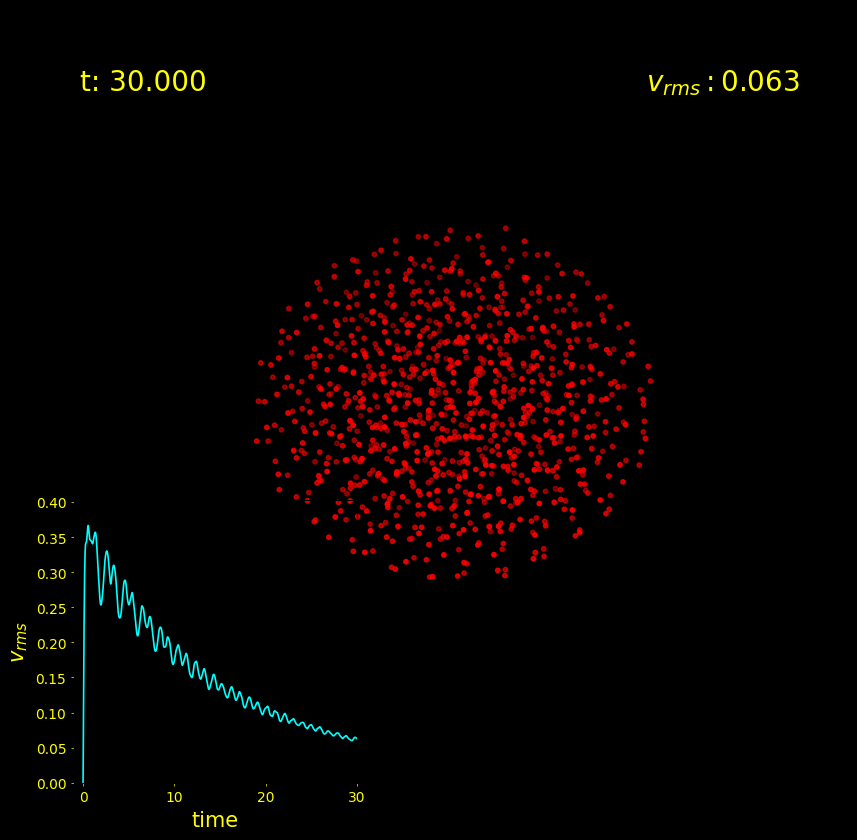

In [64]:
fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
ax = plt.subplot(1,1,1, projection='3d')
ax.set_facecolor('black')

plot_frame(3000, ax, 45, 270)

In [60]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

In [61]:
len(result_time)/12

250.08333333333334

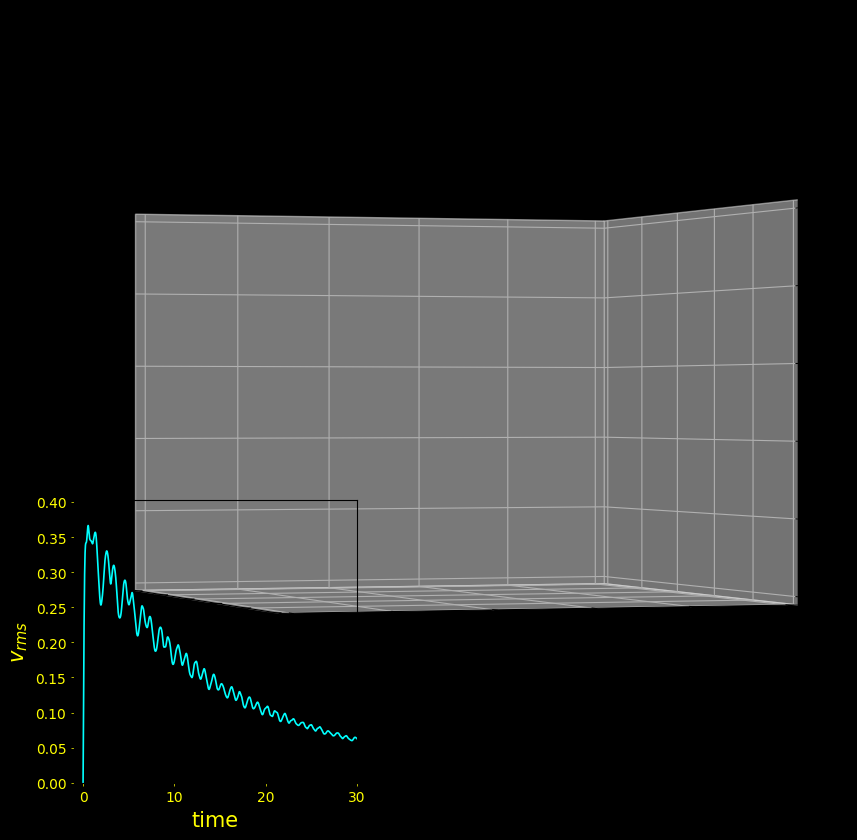

In [67]:
fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
ax = plt.subplot(1,1,1, projection='3d')
ax.set_facecolor('black')

view_angle1 = 0
view_angle2 = 270

with writer.saving(fig, 'SPH_toystar.gif',100):
     for i in range(0,len(result_time)):
        if i%12==0:
           
            #if view_angle1<45:
            #    view_angle1= view_angle1 + 0.5 
         

            view_angle2 = view_angle2 + 1
            plot_frame(i, ax, view_angle1, view_angle2)
            writer.grab_frame()
            ax.cla()